In [1]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import time

In [2]:
# ==========================================
# 2. LOAD DATASET
# ==========================================

df = pd.read_csv("used_phone_price_prediction_1M.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (1000000, 28)
     brand       model  release_year  ram_gb  storage_gb  screen_size_inches  \
0   Realme   Realme GT          2025       4         256                6.93   
1  Samsung  Galaxy S21          2024      16          64                6.29   
2    Apple   iPhone 11          2022       4         128                5.52   
3   Google     Pixel 6          2024      16         512                5.99   
4   Google     Pixel 7          2021       4         128                6.59   

   battery_capacity  processor_score  camera_score  os_type  ...  body_damage  \
0              4130               47           100  Android  ...            0   
1              5558               81            67  Android  ...            0   
2              5945               59            67      iOS  ...            0   
3              5767               84            57  Android  ...            0   
4              5336               98            44  Android  ...            0   

   

In [3]:
# ==========================================
# 3. REMOVE DUPLICATES
# ==========================================

print("Duplicates before:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("Duplicates after:", df.duplicated().sum())

Duplicates before: 0
Duplicates after: 0


In [4]:
# ==========================================
# 4. HANDLE MISSING VALUES
# ==========================================

# Numerical columns
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())


# Categorical columns
categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])


print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [5]:
# ==========================================
# 5. FEATURE ENGINEERING
# ==========================================

# Remove unwanted columns
df.drop(
    columns=[
        'screen_size_inches',
        'battery_capacity',
        'processor_score',
        'camera_score',
        'purchase_year',
        'usage_hours_per_day',
    ],
    errors='ignore',
    inplace=True
)


print("Final dataset shape:", df.shape)
print(df.columns.tolist())

Final dataset shape: (1000000, 22)
['brand', 'model', 'release_year', 'ram_gb', 'storage_gb', 'os_type', 'has_5g', 'original_price', 'age_months', 'condition', 'battery_health', 'screen_cracked', 'body_damage', 'repair_history', 'water_damage', 'city_tier', 'seller_type', 'warranty_remaining_months', 'box_available', 'charger_available', 'market_demand_score', 'resale_price']


In [6]:
# ==========================================
# 6. INPUT FEATURES AND TARGET
# ==========================================

X = df.drop(columns=['resale_price'])

y = df['resale_price']


print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (1000000, 21)
Target shape: (1000000,)


In [7]:
# ==========================================
# 7. REDUCE MEMORY USAGE
# ==========================================

num_cols_temp = X.select_dtypes(include=np.number).columns

for col in num_cols_temp:
    X[col] = X[col].astype(np.float32)


print(X.dtypes)

brand                         object
model                         object
release_year                 float32
ram_gb                       float32
storage_gb                   float32
os_type                       object
has_5g                       float32
original_price               float32
age_months                   float32
condition                     object
battery_health               float32
screen_cracked               float32
body_damage                  float32
repair_history               float32
water_damage                 float32
city_tier                     object
seller_type                   object
warranty_remaining_months    float32
box_available                float32
charger_available            float32
market_demand_score          float32
dtype: object


In [8]:
# ==========================================
# 8. IDENTIFY COLUMN TYPES
# ==========================================

categorical_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()


print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

Categorical columns:
['brand', 'model', 'os_type', 'condition', 'city_tier', 'seller_type']

Numerical columns:
['release_year', 'ram_gb', 'storage_gb', 'has_5g', 'original_price', 'age_months', 'battery_health', 'screen_cracked', 'body_damage', 'repair_history', 'water_damage', 'warranty_remaining_months', 'box_available', 'charger_available', 'market_demand_score']


In [9]:
print("Unique brands:", df['brand'].nunique())
print("Unique models:", df['model'].nunique())

Unique brands: 7
Unique models: 23


In [10]:
# ==========================================
# 9. TRAIN TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

Training shape: (800000, 21)
Testing shape : (200000, 21)


In [11]:
# ==========================================
# 10. LINEAR REGRESSION PREPROCESSOR
# ==========================================

lr_preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_cols
        ),

        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                dtype=np.float32
            ),
            categorical_cols
        )
    ]
)

In [12]:
# ==========================================
# 11. TRAIN LINEAR REGRESSION
# ==========================================

lr_model = Pipeline([
    ('preprocessor', lr_preprocessor),
    ('model', LinearRegression())
], verbose=True)


start = time.time()

lr_model.fit(X_train, y_train)

print(
    "Linear Regression training time:",
    round(time.time() - start, 2),
    "seconds"
)


y_pred_lr = lr_model.predict(X_test)

[Pipeline] ...... (step 1 of 2) Processing preprocessor, total=   2.8s
[Pipeline] ............. (step 2 of 2) Processing model, total=   1.7s
Linear Regression training time: 4.49 seconds


In [13]:
# ==========================================
# 12. TREE PREPROCESSOR
# ==========================================

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                dtype=np.float32
            ),
            categorical_cols
        )
    ],
    remainder='passthrough'
)

In [14]:
# ==========================================
# 13. TRAIN DECISION TREE
# ==========================================

dt_model = Pipeline([
    ('preprocessor', tree_preprocessor),
    (
        'model',
        DecisionTreeRegressor(
            max_depth=20,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=42
        )
    )
], verbose=True)

start = time.time()

dt_model.fit(X_train, y_train)

print(
    "Decision Tree training time:",
    round(time.time() - start, 2),
    "seconds"
)
y_pred_dt = dt_model.predict(X_test)

[Pipeline] ...... (step 1 of 2) Processing preprocessor, total=   2.2s
[Pipeline] ............. (step 2 of 2) Processing model, total=  46.2s
Decision Tree training time: 48.39 seconds


In [15]:
# ==========================================
# 14. RANDOM FOREST
# ==========================================

rf_model = Pipeline([
    ('preprocessor', tree_preprocessor),
    (
        'model',
        RandomForestRegressor(
            n_estimators=50,
            max_depth=15,
            min_samples_split=10,
            min_samples_leaf=4,
            max_features=0.7,
            random_state=42,
            n_jobs=2,
            verbose=2
        )
    )
], verbose=True)

start = time.time()

rf_model.fit(X_train, y_train)

print(
    "Random Forest training time:",
    round(time.time() - start, 2),
    "seconds"
)
y_pred_rf = rf_model.predict(X_test)

[Pipeline] ...... (step 1 of 2) Processing preprocessor, total=   2.2s
building tree 1 of 50
building tree 2 of 50


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


building tree 3 of 50
building tree 4 of 50
building tree 5 of 50
building tree 6 of 50
building tree 7 of 50
building tree 8 of 50
building tree 9 of 50
building tree 10 of 50
building tree 11 of 50
building tree 12 of 50
building tree 13 of 50
building tree 14 of 50
building tree 15 of 50
building tree 16 of 50
building tree 17 of 50
building tree 18 of 50
building tree 19 of 50
building tree 20 of 50
building tree 21 of 50
building tree 22 of 50
building tree 23 of 50
building tree 24 of 50
building tree 25 of 50
building tree 26 of 50
building tree 27 of 50
building tree 28 of 50
building tree 29 of 50
building tree 30 of 50
building tree 31 of 50
building tree 32 of 50
building tree 33 of 50
building tree 34 of 50
building tree 35 of 50
building tree 36 of 50
building tree 37 of 50
building tree 38 of 50
building tree 39 of 50


[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:  6.2min


building tree 40 of 50
building tree 41 of 50
building tree 42 of 50
building tree 43 of 50building tree 44 of 50

building tree 45 of 50
building tree 46 of 50
building tree 47 of 50
building tree 48 of 50
building tree 49 of 50
building tree 50 of 50


[Parallel(n_jobs=2)]: Done  50 out of  50 | elapsed:  8.1min finished


[Pipeline] ............. (step 2 of 2) Processing model, total= 8.1min
Random Forest training time: 489.39 seconds


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:    1.2s
[Parallel(n_jobs=2)]: Done  50 out of  50 | elapsed:    1.6s finished


In [21]:

models = {
    'Linear Regression': lr_model,
    'Decision Tree': dt_model,
    'Random Forest': rf_model
}

train_results = []

for name, model in models.items():

    # Predict using training data
    y_train_pred = model.predict(X_train)

    # Calculate training metrics
    mae = mean_absolute_error(y_train, y_train_pred)
    mse = mean_squared_error(y_train, y_train_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_train, y_train_pred)

    train_results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

train_results_df = pd.DataFrame(train_results)

display(train_results_df.sort_values(
    by='R2 Score',
    ascending=False
))

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:    8.6s
[Parallel(n_jobs=2)]: Done  50 out of  50 | elapsed:   11.6s finished


,Model,MAE,MSE,RMSE,R2 Score
1,Decision Tree,1546.860835,4.976027e+06,2230.700905,0.982024
2,Random Forest,2459.632192,1.122091e+07,3349.763075,0.959464
0,Linear Regression,4795.359876,4.634494e+07,6807.711653,0.832578


In [16]:
# ==========================================
# 15. EVALUATION FUNCTION
# ==========================================

def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(
        y_true,
        y_pred
    )
    mse = mean_squared_error(
        y_true,
        y_pred
    )
    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_true,
        y_pred
    )
    return {
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }

In [17]:
# ==========================================
# 16. COMPARE ALL MODELS
# ==========================================

results = [

    evaluate_model(
        "Linear Regression",
        y_test,
        y_pred_lr
    ),

    evaluate_model(
        "Decision Tree",
        y_test,
        y_pred_dt
    ),

    evaluate_model(
        "Random Forest",
        y_test,
        y_pred_rf
    )
]


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='R2 Score',
    ascending=False
)

print(results_df)

               Model          MAE           MSE         RMSE  R2 Score
2      Random Forest  2764.269099  1.404646e+07  3747.860849  0.949705
1      Decision Tree  3154.989852  1.803545e+07  4246.816322  0.935422
0  Linear Regression  4794.850228  4.658926e+07  6825.632877  0.833182


In [18]:
new_phone = pd.DataFrame([{
    'brand': 'Samsung',
    'model': 'Galaxy S23',
    'release_year': 2023,
    'ram_gb': 8,
    'storage_gb': 256,
    'os_type': 'Android',
    'has_5g': 1,
    'original_price': 75000,
    'age_months': 26,
    'condition': 'Good',
    'battery_health': 100,
    'screen_cracked': 0,
    'body_damage': 0,
    'repair_history': 0,
    'water_damage': 0,
    'city_tier': 'Tier1',
    'seller_type': 'Individual',
    'warranty_remaining_months': 0,
    'box_available': 1,
    'charger_available': 1,
    'market_demand_score': 54
}])

predicted_price = rf_model.predict(new_phone)

print("Predicted Resale Price:", round(predicted_price[0], 2))

Predicted Resale Price: 24484.41


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done  50 out of  50 | elapsed:    0.0s finished


In [19]:
import joblib

joblib.dump(rf_model, "random_forest_model_3.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [20]:
loaded_model = joblib.load("random_forest_model_3.pkl")

prediction = loaded_model.predict(new_phone)

print("Predicted Resale Price: ₹", round(prediction[0], 2))

Predicted Resale Price: ₹ 24484.41


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done  50 out of  50 | elapsed:    0.0s finished


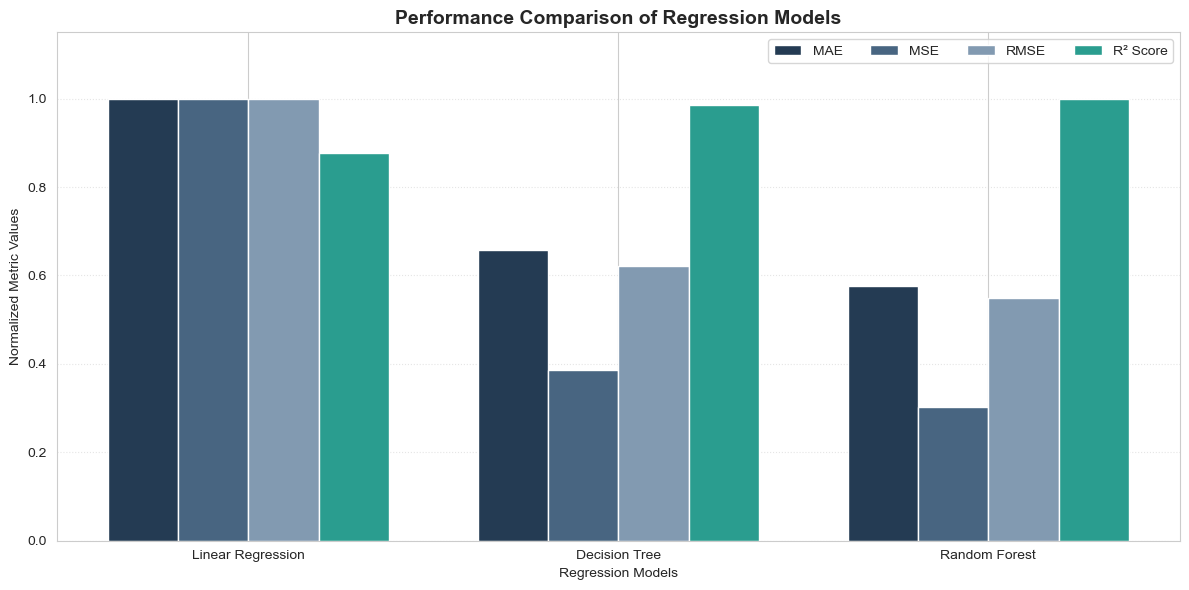

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Model names
models = ['Linear Regression', 'Decision Tree', 'Random Forest']

# Actual testing results
mae = np.array([4794.85, 3154.99, 2764.27])
mse = np.array([46589260, 18035450, 14046460])
rmse = np.array([6825.63, 4246.82, 3747.86])
r2 = np.array([0.833182, 0.935422, 0.949705])

# Normalize values for visualization
# Original values remain unchanged
mae_norm = mae / mae.max()
mse_norm = mse / mse.max()
rmse_norm = rmse / rmse.max()
r2_norm = r2 / r2.max()

x = np.arange(len(models))
width = 0.19

plt.figure(figsize=(12, 6))

plt.bar(x - 1.5*width, mae_norm, width,
        label='MAE', color='#243B53')

plt.bar(x - 0.5*width, mse_norm, width,
        label='MSE', color='#486581')

plt.bar(x + 0.5*width, rmse_norm, width,
        label='RMSE', color='#829AB1')

plt.bar(x + 1.5*width, r2_norm, width,
        label='R² Score', color='#2A9D8F')

plt.xticks(x, models)
plt.ylabel('Normalized Metric Values')
plt.xlabel('Regression Models')

plt.title(
    'Performance Comparison of Regression Models',
    fontsize=14,
    fontweight='bold'
)

plt.ylim(0, 1.15)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.legend(loc='upper right', ncol=4)

plt.tight_layout()

plt.savefig(
    'grouped_model_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()